In [1]:
#Avani Gohil 
#USC ID: 8561210879

In [2]:
#Imports

from pathlib import Path
import pandas as pd
import numpy as np
import os
import re
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

#Classification
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, cross_val_score
from sklearn.feature_selection import RFE
from sklearn.naive_bayes import GaussianNB, MultinomialNB

#Statistics
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, RocCurveDisplay, roc_auc_score
from sklearn.base import clone

In [3]:
#From HW3: Loading AReM data

data_dir = Path("HW3_4/AReM")
csv_data = sorted(data_dir.glob("*/*.csv"))

#Except to download 88 files
print(f"Found {len(csv_data)} files")

#Defining columns for csvs

columns = [
    "time", "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"
]

dfs = {}

for csv_path in csv_data:
    name = csv_path.relative_to(data_dir).as_posix()
    try:
        df = pd.read_csv(
            csv_path,
            sep=r"[,\s]+",
            engine="python",
            comment="#",
            header=None,
            usecols=range(7)  #only reading 7 cols and ignoring extra comma on cycling/dataset14.csv for 8th col using this range restriction
        )
        df.columns = columns
        dfs[name] = df
    except Exception as error:
        print("Failed on:", name)
        print(error)
        break

assert len(dfs) == 88, f"Expected 88 datasets, loaded {len(dfs)}"
print("Loaded datasets:", len(dfs))

Found 88 files
Loaded datasets: 88


In [4]:
#From HW3: Training and Testing Dataset Folders

#instructions: keep datasets 1 and 2 of bending 1/2 and datasets 1-3 for all other activities as testing. The rest as training data. 

test_data = {}
train_data = {} 

for name, df in dfs.items():
    #grouping elements of csv path file to extract activity name and dataset number
    match = re.fullmatch(r"([^/]+)/dataset(\d+)\.csv", name)

    activity = match.group(1)
    ds_number = int(match.group(2))
    
    #assigning datasets to testing dataset
    if activity in {"bending1", "bending2"}:
        test_matches = ds_number <= 2
    else:
        test_matches = ds_number <= 3

    #populating the dictionaries
    if test_matches:
        test_data[name] = df
    else:
        train_data[name] = df

print(f"The testing dataset is composed of {len(test_data)} and the training dataset {len(train_data)} files each.")
print(test_data)
print(train_data)

The testing dataset is composed of 19 and the training dataset 69 files each.
{'bending1/dataset1.csv':        time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
0         0      39.25       0.43      22.75       0.43      33.75        1.3
1       250      39.25       0.43      23.00       0.00      33.00        0.0
2       500      39.25       0.43      23.25       0.43      33.00        0.0
3       750      39.50       0.50      23.00       0.71      33.00        0.0
4      1000      39.50       0.50      24.00       0.00      33.00        0.0
..      ...        ...        ...        ...        ...        ...        ...
475  118750      43.33       0.47      25.00       0.00      30.00        0.0
476  119000      43.50       0.50      25.50       0.50      30.00        0.0
477  119250      43.50       0.50      24.75       0.43      30.00        0.0
478  119500      43.50       0.50      24.33       0.47      30.00        0.0
479  119750      43.50       0.50     

In [5]:
#From HW3: Extracting time-domain features for all instances (88 CSV files total)

#looping through each CSV/df

feature_summary = {}

for name, df in dfs.items():
    row = {}

    for i, col in enumerate(columns[1:], start=1):  # skipping the time column and loading the 6 time-domain features
        series = df[col]

        row[f"Min{i}"] = series.min()
        row[f"Max{i}"] = series.max()
        row[f"Mean{i}"] = series.mean()
        row[f"Median{i}"] = series.median()
        row[f"Standard_Deviation{i}"] = series.std()
        row[f"1st_Quartile{i}"] = series.quantile(0.25)
        row[f"3rd_Quartile{i}"] = series.quantile(0.75)

    feature_summary[name] = row

feature_df = pd.DataFrame.from_dict(feature_summary, orient="index")
feature_df.index.name = "instance"  #for each index assign instance tag to first column

#print(feature_summary) #should output the full dictionary view

print(feature_df) #output the new dataset with 88 instances/rows

                        Min1   Max1      Mean1  Median1  Standard_Deviation1  \
instance                                                                       
bending1/dataset1.csv  37.25  45.00  40.624792   40.500             1.476967   
bending1/dataset2.csv  38.00  45.67  42.812812   42.500             1.435550   
bending1/dataset3.csv  35.00  47.40  43.954500   44.330             1.558835   
bending1/dataset4.csv  33.00  47.75  42.179812   43.500             3.670666   
bending1/dataset5.csv  33.00  45.75  41.678063   41.750             2.243490   
...                      ...    ...        ...      ...                  ...   
walking/dataset5.csv   20.75  46.25  34.763333   35.290             4.742208   
walking/dataset6.csv   21.50  51.00  34.935812   35.500             4.645944   
walking/dataset7.csv   18.33  47.67  34.333042   34.750             4.948770   
walking/dataset8.csv   18.33  45.75  34.599875   35.125             4.731790   
walking/dataset9.csv   15.50  43.67  34.

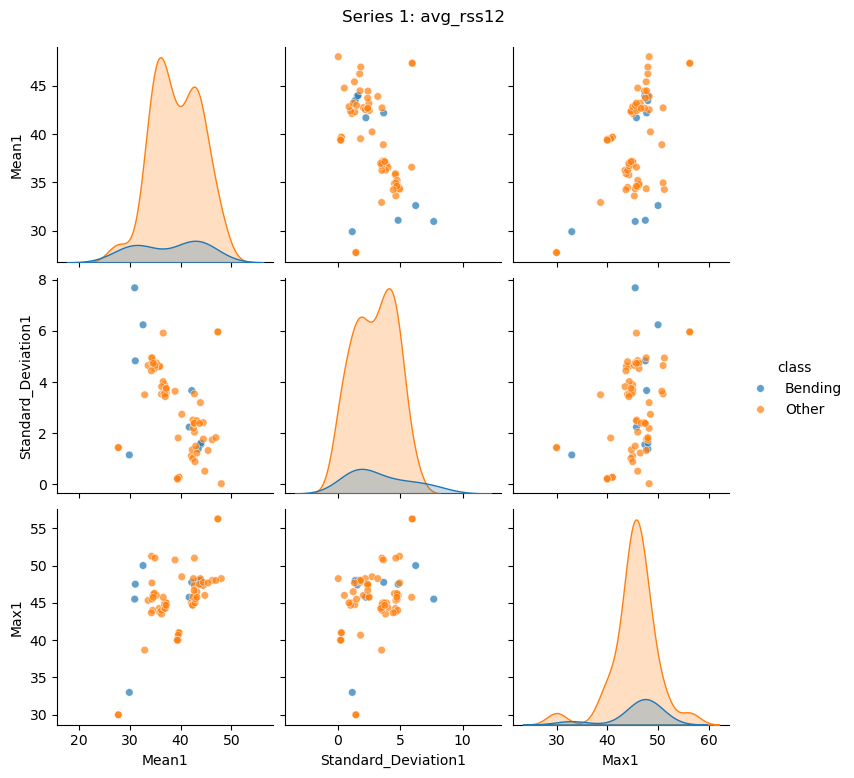

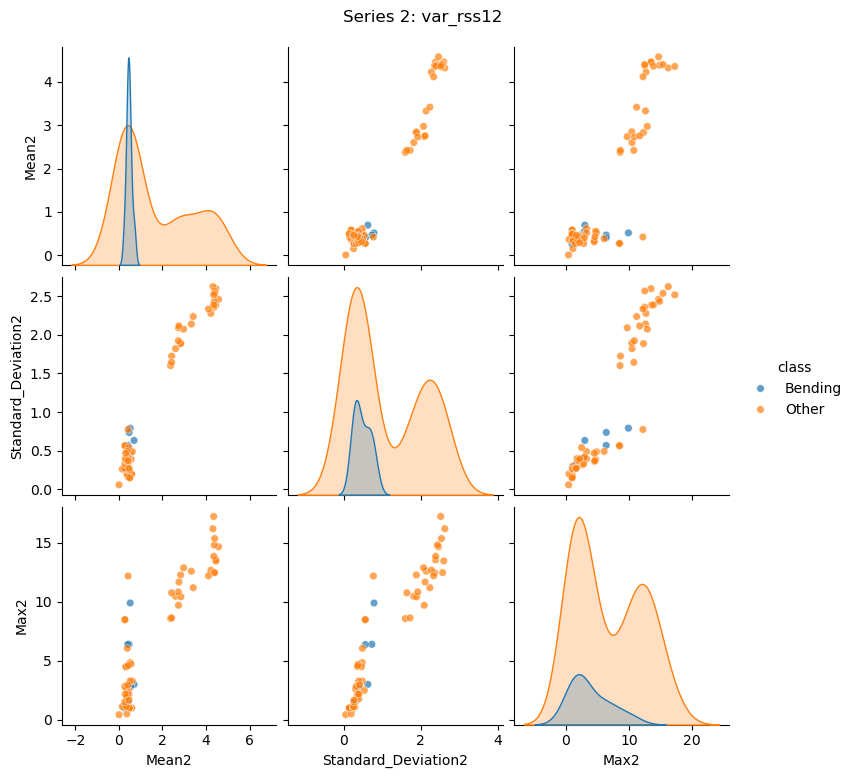

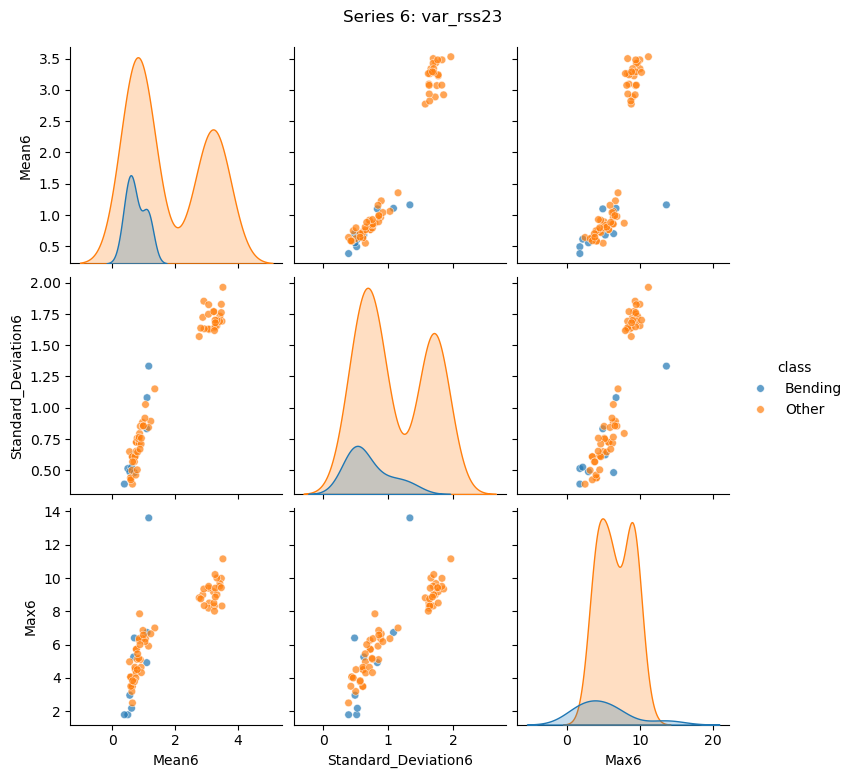

In [6]:
#Start of HW4 - Time Series Classification Pt.2 (Binary and Multiclass Classification)
#Binary classfication of class = 1 (bending) and class = 0 (other activities)


#2a i.) Scatterplots of Extracted Features

train_features = feature_df.loc[list(train_data)].copy()

train_features["class"] = [
    "Bending" if name.split("/")[0] in {"bending1", "bending2"}
    else "Other"
    for name in train_features.index
]

#Just looping through time series 1,2,6

series_names = {1: "avg_rss12", 2: "var_rss12", 6: "var_rss23"}

for i, series_name in series_names.items():
    features = [f"Mean{i}", f"Standard_Deviation{i}", f"Max{i}"]

    grid = sns.pairplot(
        train_features,
        vars=features,
        hue="class",
        height=2.5,
        plot_kws={"alpha": 0.7, "s": 30}
    )
    grid.fig.suptitle(f"Series {i}: {series_name}", y=1.03)
    plt.show()

(69, 36)


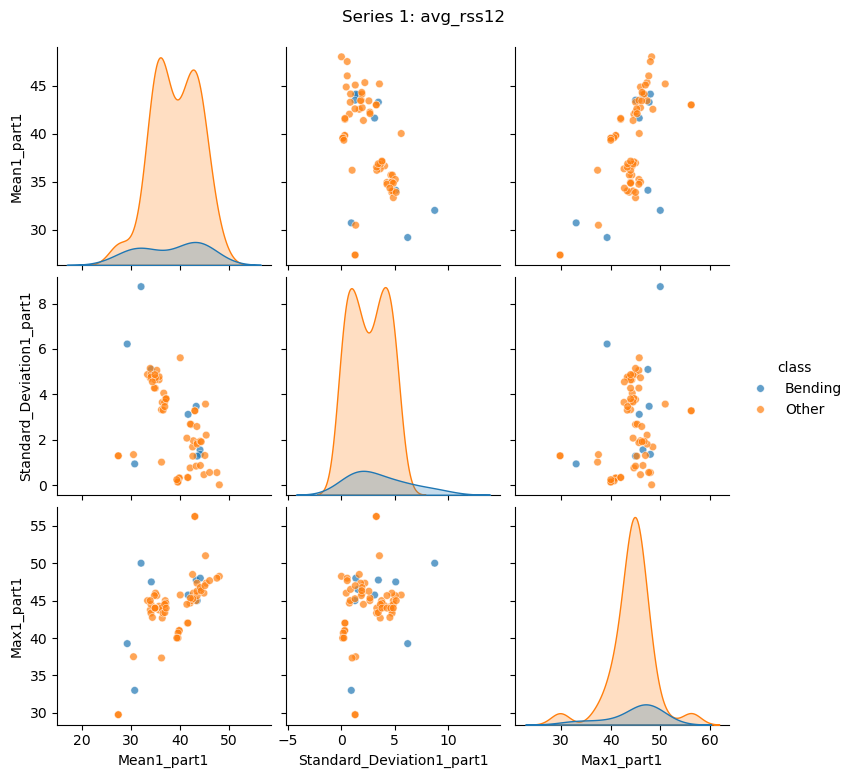

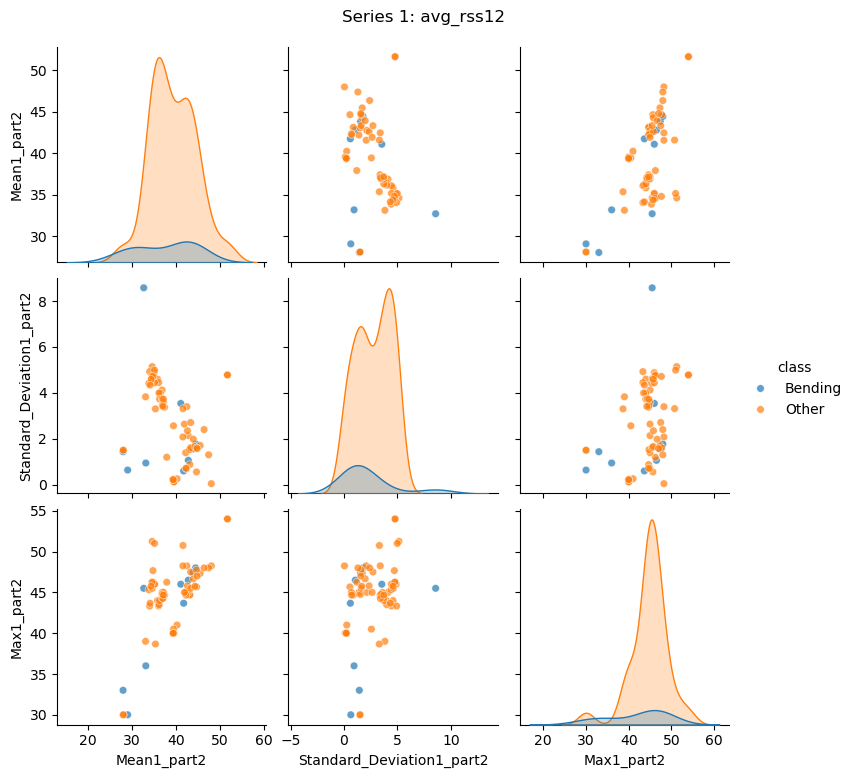

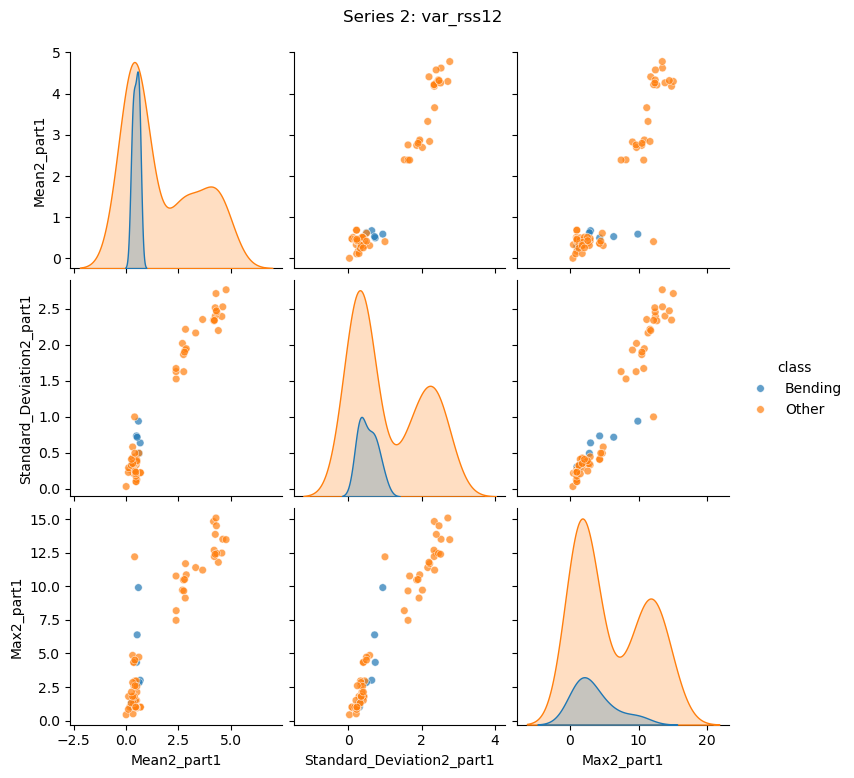

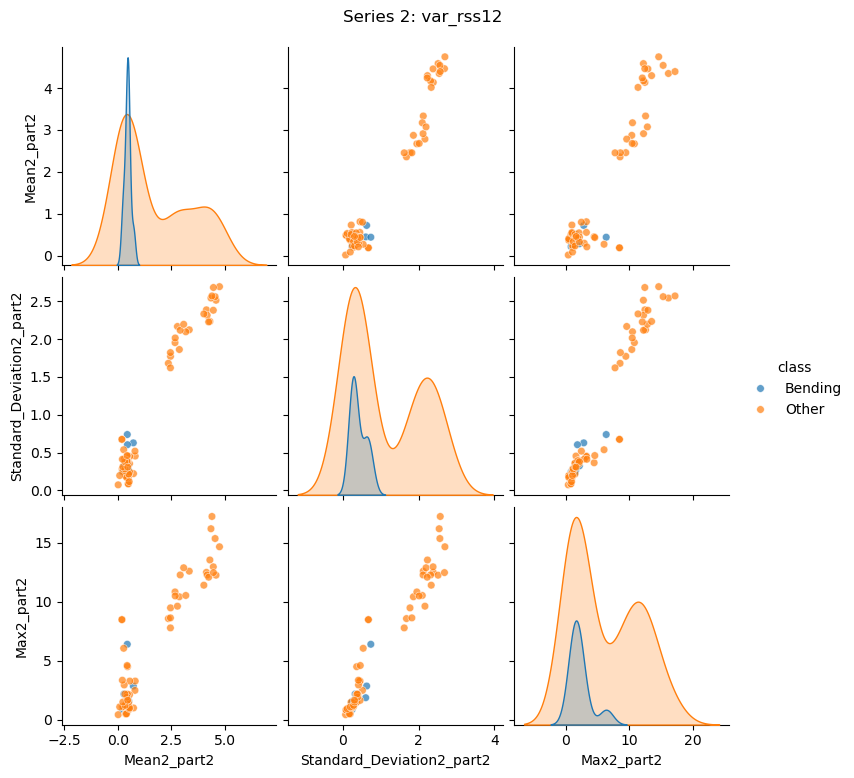

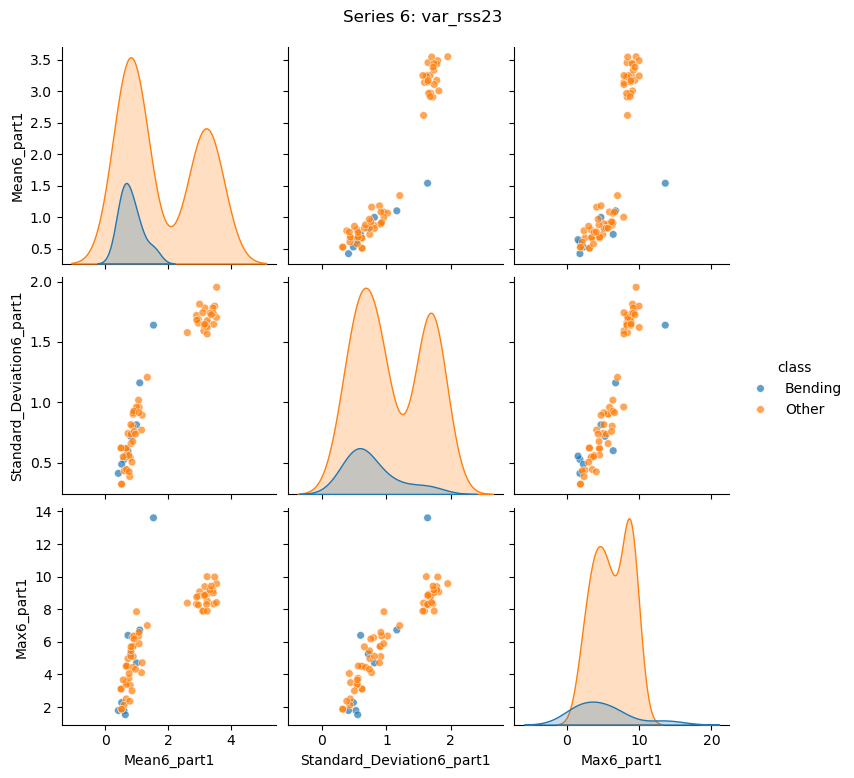

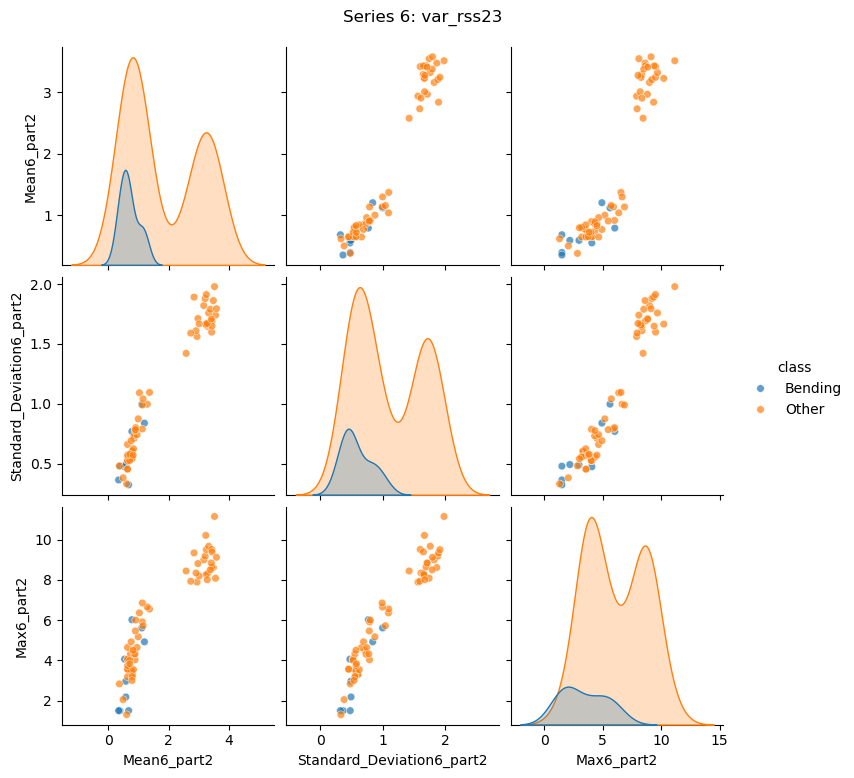

In [7]:
#2a ii.) Split training data in half, and redo scatterplots


#Splitting training data

new_feature_calc = {}

for name, df in train_data.items():
    
    midpoint = len(df) // 2

    split_data = [df.iloc[:midpoint], df.iloc[midpoint:]]

    row = {} #store new calculations for both data halves

    #Calculating mean, SD, and max 
    
    for part_number, half in enumerate(split_data, start=1):
            for series_number, column in enumerate(columns[1:], start=1):  
                row[f"Mean{series_number}_part{part_number}"] = half[column].mean()
                row[f"Standard_Deviation{series_number}_part{part_number}"] = half[column].std()
                row[f"Max{series_number}_part{part_number}"] = half[column].max()
    
    new_feature_calc[name] = row
    
    split_feature_df = pd.DataFrame.from_dict(new_feature_calc, orient="index")

split_feature_df = pd.DataFrame.from_dict(new_feature_calc, orient="index")
print(split_feature_df.shape)



#Defining bending versus other files
split_feature_df["class"] = [
    "Bending" if name.split("/")[0] in {"bending1", "bending2"}
    else "Other"
    for name in split_feature_df.index
]



#Repeat - Just looping through time series 1,2,6

series_names = {1: "avg_rss12", 2: "var_rss12", 6: "var_rss23"}

for i, series_name in series_names.items():
    
    for part_number in (1, 2):
            features = [
                f"Mean{i}_part{part_number}",
                f"Standard_Deviation{i}_part{part_number}",
                f"Max{i}_part{part_number}"
            ]
    
            grid = sns.pairplot(
                split_feature_df,
                vars=features,
                hue="class",
                height=2.5,
                plot_kws={"alpha": 0.7, "s": 30}
            )
        
            grid.fig.suptitle(f"Series {i}: {series_name}", y=1.03)
            plt.show()

2aii.) Question / Response

I don't see a considerable difference in the mean, standard deviation, and max distribution for the Standing CSVs versus the Other CSVs when we divided each segement into 2 halves, and compared the output with the whole series plots. This signals that the spread of sensory data (measured through RSS) has similar summary statistics even when we partition the data in half. Through cross-validation we can see if segmenting the data helps to reduce validation error for a more refined model. 

In [8]:
#2aiii.) Doing l splits to stetup for Binary Classification

#General Instructions: 
#(l=1\): Keep each sensor series whole. For a 480-row file, each segment has 480 values.
#(l=2\): Split each series into two halves of about 240 values.
#(l=3\): Split each series into three parts of about 160 values.

def segment_split(data_dict, l):
    feature_rows = {}

    for name, df in data_dict.items():
        row = {}

        segments = np.array_split(np.arange(len(df)), l)  #provides an approx. split based on num of segments, l

        for part_number, positions in enumerate(segments, start=1):
            segment = df.iloc[positions]

            #Calculating summary stats
            for series_number, column in enumerate(columns[1:], start=1):
                row[f"Mean{series_number}_part{part_number}"] = segment[column].mean()
                row[f"Standard_Deviation{series_number}_part{part_number}"] = segment[column].std()
                row[f"Max{series_number}_part{part_number}"] = segment[column].max()

        feature_rows[name] = row

    return pd.DataFrame.from_dict(feature_rows, orient="index")
    

train_features_by_l = {}

for l in range(1, 21):
    train_features_by_l[l] = segment_split(train_data, l)
    print(f"l={l}: {train_features_by_l[l].shape}")


l=1: (69, 18)
l=2: (69, 36)
l=3: (69, 54)
l=4: (69, 72)
l=5: (69, 90)
l=6: (69, 108)
l=7: (69, 126)
l=8: (69, 144)
l=9: (69, 162)
l=10: (69, 180)
l=11: (69, 198)
l=12: (69, 216)
l=13: (69, 234)
l=14: (69, 252)
l=15: (69, 270)
l=16: (69, 288)
l=17: (69, 306)
l=18: (69, 324)
l=19: (69, 342)
l=20: (69, 360)


In [9]:
#2aiii.) Logistic, Binary Classification

#call the train_features_by_l dict
lr_results = []
cross_val = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  #5-fold cross-validation

for l in range(1, 21):
    X = train_features_by_l[l]

    y = X.index.to_series().apply(
        lambda name: int(name.split("/")[0] in {"bending1", "bending2"})
    )

    for p in [3, 6, 9, 12, 18]:  #iterating over num of features for RFE method
        if p > X.shape[1]:
            continue

        lr_model = make_pipeline(
            StandardScaler(),
            RFE(
                LogisticRegression(C=1e6, max_iter=100),
                n_features_to_select=p,
                step=0.2
            ),
            LogisticRegression(C=1e6, max_iter=100)
        )

        scores = cross_val_score(
            lr_model, X, y,
            cv=cross_val,
            scoring="accuracy"
        )

        lr_results.append({
            "l": l,
            "p": p,
            "mean_CV_accuracy": scores.mean()  #provides the average validation accuracy across 5-fold validation process
        })

#Seeing the combination of segment size and optimal predictor selection based on CV accuracy 
results_df = pd.DataFrame(lr_results)
display(results_df.sort_values("mean_CV_accuracy", ascending=False).head(10))

#Reviewing the class imbalance
print("Counts (0=Other, 1=Bending):")
print(y.value_counts())

print("\nProportions:")
print(y.value_counts(normalize=True).round(3))

#I am going to choose l=12 and 9 predictors as my combination since it has the lowest cross-validation error.


,l,p,mean_CV_accuracy
57,12,9,0.971429
84,17,18,0.971429
58,12,12,0.957143
49,10,18,0.957143
38,8,12,0.957143
36,8,6,0.957143
34,7,18,0.957143
29,6,18,0.957143
28,6,12,0.957143
26,6,6,0.957143


Counts (0=Other, 1=Bending):
0    60
1     9
Name: count, dtype: int64

Proportions:
0    0.87
1    0.13
Name: proportion, dtype: float64


#2aiii.) Cross-Validation Technique Discussion

The structure of this dataset is that we are pulling 3 core statistical summaries - mean, standard devitation, and maximum - value of the time-sensitive sensory inputs for 6 core predictors (combinations of the sensors placed tracking activity/movements). Since we are testing many splits of the data, we multiply the amount of features that were are training the logistic regression model on. For example, with 2 segments of the data, we have the core 6 predictors * 2 (for each segment split) = 12 predictors, and have 54 predictors when we split the data into 9 segments. There is a right and wrong way of doing cross-validation. The wrong method is doing all the methods of cross-validation amongst the whole dataset - feature selection, scaling, and outlier removal - so doing all of these outside of the cross-validation loops leads to data leakage/contamination of the model validation/testing. Therefore, the best method of cross-validation is to do cross-validation on every fold, split the data first, run feature selection/scaling only on the training portion of that fold, transform the validation portion using those parameters, and then evaluate the model.

Additionally, with each segmentation of the training data, we need to be aware of class imbalance. As seen in the previous output, the clasification into class 0 or 'Other' is 87% and the classification of '1' which is bending class is 13%. With class imabalance, there is the risk of each validation set not sampling a sufficient ratio of the Other and Bending class in each fold/split, and possibly having no files from the Standing dataset. So, with the stratified cross-validation, the stratified cross-validation function splits your training CSV instances into cross-validation folds while keeping the Bending/Other proportions approximately similar in each fold.


,Final_Model_Beta
Max5_part1,1.615899
Mean5_part2,4.850886
Standard_Deviation5_part2,-2.044192
Max5_part3,4.021425
Mean5_part4,2.419325
Max5_part4,5.013117
Standard_Deviation3_part6,-3.630312
Standard_Deviation5_part7,-1.809965
Max6_part11,-3.451156


Intercept: -10.708090705600425


,Parameter,Estimated_Theta,P_Value
0,Intercept,-10.708091,<NA>
1,Max5_part1,1.615899,<NA>
2,Mean5_part2,4.850886,<NA>
3,Standard_Deviation5_part2,-2.044192,<NA>
4,Max5_part3,4.021425,<NA>
5,Mean5_part4,2.419325,<NA>
6,Max5_part4,5.013117,<NA>
7,Standard_Deviation3_part6,-3.630312,<NA>
8,Standard_Deviation5_part7,-1.809965,<NA>
9,Max6_part11,-3.451156,<NA>


,Predicted Other,Predicted Bending
Actual Other,60,0
Actual Bending,0,9


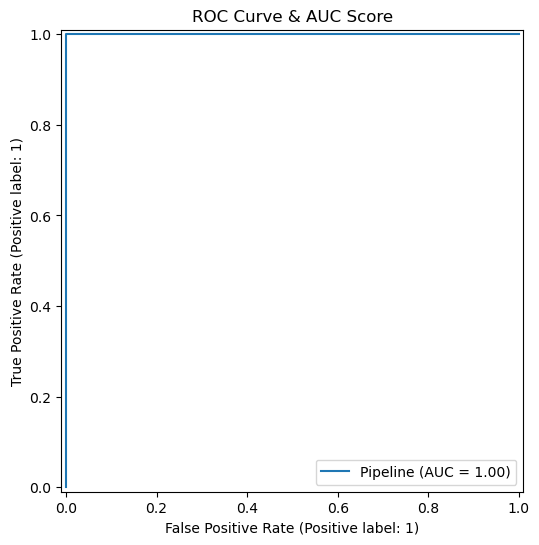

In [10]:
#2aiv.) Report the confusion matrix and show the ROC and AUC for your classifier on train data

best = results_df.sort_values("mean_CV_accuracy", ascending=False).iloc[0]
best_l, best_p = int(best["l"]), int(best["p"])

X = train_features_by_l[best_l]
y = X.index.to_series().apply(
    lambda name: int(name.split("/")[0] in {"bending1", "bending2"})
)

final_model = make_pipeline(
    StandardScaler(),
    RFE(LogisticRegression(C=1e6, max_iter=100),
        n_features_to_select=best_p, step=0.2),
    LogisticRegression(C=1e6, max_iter=100)
)

final_model.fit(X, y)
train_predictions = final_model.predict(X)

#Report the parameters of your logistic regression estimated thetas as well as the p-values associated with them.
selected = final_model.named_steps["rfe"].support_
selected_names = X.columns[selected]

# Betas of final fitted model
lr = final_model.named_steps["logisticregression"]

final_betas = pd.Series(
    lr.coef_[0],
    index=selected_names,
    name="Final_Model_Beta"
)
display(final_betas.to_frame())
print("Intercept:", lr.intercept_[0])

# On features, calculate p-values
selected_names = X.columns[final_model.named_steps["rfe"].support_]
lr = final_model.named_steps["logisticregression"]

parameter_table = pd.DataFrame({
    "Parameter": ["Intercept", *selected_names],
    "Estimated_Theta": [lr.intercept_[0], *lr.coef_[0]],
    "P_Value": [pd.NA] * (len(selected_names) + 1)
})

#It doesn't report valid p-values since the final classifier has perfect classfication

display(parameter_table)

#Creating the confusion matrix
cm = confusion_matrix(y, train_predictions, labels=[0, 1])

cm_table = pd.DataFrame(
    cm,
    index=["Actual Other", "Actual Bending"],
    columns=["Predicted Other", "Predicted Bending"]
)

display(cm_table)

#ROC and AUC Curve
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_estimator(final_model, X, y, pos_label=1, ax=ax)

# Add custom graph formatting
ax.set_title("ROC Curve & AUC Score")
plt.show()

In [11]:
#2v.) Execute Classifier on Test Set

#Getting the predictors from the test data set
X_test =segment_split(test_data, best_l)
X_test = X_test[X.columns]  

y_test = X_test.index.to_series().apply(
    lambda name: int(name.split("/")[0] in {"bending1", "bending2"}))  #fitting the predicted values into the classes

#Fitting the model and getting accuracy
test_predicts = final_model.predict(X_test)  #calling the scaler regression and RFE process here
test_accuracy = accuracy_score(y_test, test_predicts)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Average cross-validation accuracy: {best['mean_CV_accuracy']:.3f}")
print(f"{len(y_test)} files in the test set.")

#Confusion Matrix
test_cm = pd.DataFrame(
    confusion_matrix(y_test, test_predicts, labels=[0, 1]),
    index=["Actual Other", "Actual Bending"],
    columns=["Predicted Other", "Predicted Bending"], 
)

display(test_cm)

Test accuracy: 0.947
Average cross-validation accuracy: 0.971
19 files in the test set.


,Predicted Other,Predicted Bending
Actual Other,15,0
Actual Bending,1,3


2vi.) 

Do your classes seem well seperated to cause instability in calculating logistic regression parameters?

Yes, based on the confusion matrix from the training dataset, we can see that we get 100% accuracy of classifying the activity files into "Bending" or "Other" which leads to the p-values being unable to be calcuated, with a N/A outcome. P-values refer to the probability of the null hypothesis where sensory data inputs does not have an association to prediciting activity labels. During the training phase, the features selected led to 100% accuracy in the final model, with the cross-validation accuracy having 97.1% accuracy which means that every fold didn't have 100% accuracy like the final model. Additionally, as seen with the test accuracy, the model predicts the correct classes with 94.7% accuracy. 


2vii.)

From the confusion matrices, do you see an imbalanced class? 

Yes, as seen with both confusion matrices, the Bending class only comprises of roughly 13% of files, leading to class imbalance. This is moderate class imbalance, where the model does well on guessing the majority class (Other in this case) most of the time, leading to a misleading accuracy score where the minority class (Bending in this case) may not be interpreted into its correct class enough.

Original training counts: {0: 60, 1: 9}
Sampled training counts: {0: 60, 1: 60}
Original-training accuracy: 1.0
Intercept adjustment: -1.8971199848858813


,Predicted Other,Predicted Bending
Actual Other,60,0
Actual Bending,0,9


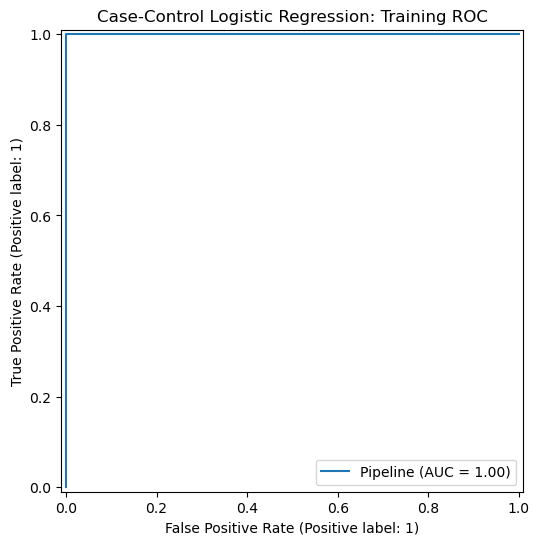

In [12]:
#2vii.) Logisitic Regression Model with Case-Control Modeling

# Use the training features at your chosen best_l
X_other = X.loc[y == 0]
X_bending = X.loc[y == 1]

# Sample Bending instances with replacement to balance the classes
X_bending_sampled = X_bending.sample(
    n=len(X_other),
    replace=True,
    random_state=42
)

X_case = pd.concat([X_other, X_bending_sampled])
y_case = pd.Series(
    [0] * len(X_other) + [1] * len(X_bending_sampled),
    index=X_case.index
)

print("Original training counts:", y.value_counts().to_dict())
print("Sampled training counts:", y_case.value_counts().to_dict())

# Fit a separate copy of your chosen pipeline
case_model = clone(final_model)
case_model.fit(X_case, y_case)

# Adjust the intercept for the original training class proportions
original_odds = y.sum() / (len(y) - y.sum())
sampled_odds = y_case.sum() / (len(y_case) - y_case.sum())
intercept_adjustment = np.log(original_odds / sampled_odds)

case_model.named_steps["logisticregression"].intercept_[0] += intercept_adjustment


case_predictions = case_model.predict(X)

case_cm = pd.DataFrame(
    confusion_matrix(y, case_predictions, labels=[0, 1]),
    index=["Actual Other", "Actual Bending"],
    columns=["Predicted Other", "Predicted Bending"]
)

print("Original-training accuracy:", accuracy_score(y, case_predictions))
print("Intercept adjustment:", intercept_adjustment)
display(case_cm)

#Display of ROC and AUC
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_estimator(case_model, X, y, pos_label=1, ax=ax)
ax.set_title("Case-Control Logistic Regression: Training ROC")
plt.show()

In [13]:
#2bi.) Binary Classification Using Regularization in the Logistic Regression

lasso_results = []
lasso_models = {}

#cross-validation and c values which are inverse of lambda
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
C_values = [0.01, 0.1, 1, 10, 100]

for l in range(1, 21):
    X_lasso = train_features_by_l[l]
    y_lasso = X_lasso.index.to_series().apply(
        lambda name: int(name.split("/")[0] in {"bending1", "bending2"})
    )

    pipeline = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=5000,
            random_state=42
        )
    )

    search = GridSearchCV(
        pipeline,
        {"logisticregression__C": C_values},
        cv=cv,
        scoring="accuracy"
    )
    search.fit(X_lasso, y_lasso)

    model = search.best_estimator_
    lasso_models[l] = model

    lasso_results.append({
        "l": l,
        "best_C": search.best_params_["logisticregression__C"],
        "CV_accuracy": search.best_score_,
        "CV_error": 1 - search.best_score_,
        "features_kept": np.count_nonzero(
            model.named_steps["logisticregression"].coef_[0]
        )
    })

l1_table = pd.DataFrame(lasso_results)
display(l1_table.sort_values("CV_error").head(10))


,l,best_C,CV_accuracy,CV_error,features_kept
19,20,10,0.971429,0.028571,13
11,12,10,0.971429,0.028571,12
18,19,1,0.971429,0.028571,8
17,18,1,0.957143,0.042857,11
16,17,1,0.957143,0.042857,10
13,14,1,0.957143,0.042857,8
0,1,10,0.957143,0.042857,7
2,3,1,0.957143,0.042857,9
9,10,10,0.957143,0.042857,15
7,8,100,0.942857,0.057143,21


#2bii.)

I compared L1-penalized logistic regression with RFE, the permitted alternative to p-value-based feature selection. The best L1 model used 20 segments and retained 13 predictors, achieving 97.1% mean cross-validation accuracy. The best RFE model used 12 segments and retained 9 predictors, also achieving 97.1% accuracy in the cross-validation. Neither performed better by this measure but RFE produced the smaller final model. L1 was easier to implement for feature selection because the penalty set coefficients to zero during fitting, whereas RFE required choosing the number of features to retain which is more computationally expensive. Also, having p-value selection was difficult for this dataset because the training classes were perfectly separated, so that wasn't a metric we can compare model performance with. 

,l,best_C,CV_accuracy
1,2,100,0.913399
0,1,10,0.898693
5,6,100,0.898693
4,5,100,0.869281
3,4,100,0.856209
8,9,10,0.856209
2,3,100,0.855392
6,7,100,0.840686
12,13,100,0.840686
17,18,1,0.839869


Best l value: 2
Best C value: 100.0
CV accuracy: 0.913
Test files: 19
Test accuracy: 0.842
Test error: 0.158


,Predicted bending1,Predicted bending2,Predicted cycling,Predicted lying,Predicted sitting,Predicted standing,Predicted walking
Actual bending1,2,0,0,0,0,0,0
Actual bending2,0,1,0,0,1,0,0
Actual cycling,0,0,3,0,0,0,0
Actual lying,0,0,0,3,0,0,0
Actual sitting,1,0,0,0,1,1,0
Actual standing,0,0,0,0,0,3,0
Actual walking,0,0,0,0,0,0,3


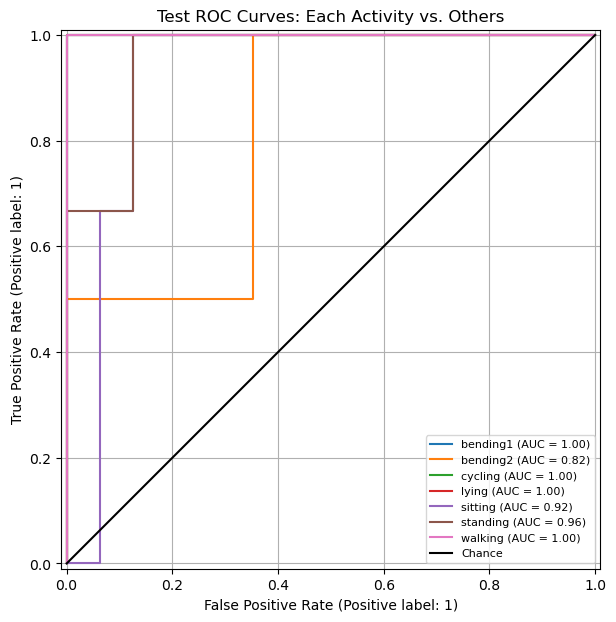

Macro-average test AUC: 0.957


In [14]:
#2ci.) Multi-Class Classification

#Lasso penalized multinomial regression model

multiclass_results = []
multiclass_models = {}

#Same method of looping around 20 segmented sizes of the dataset
for l in range(1, 21):
    X_l = train_features_by_l[l]

    # Now pulling activity level data for the classes
    y_l = X_l.index.to_series().str.split("/").str[0]

    # Doing k-fold
    n_folds = min(5, y_l.value_counts().min())
    cv = StratifiedKFold(
        n_splits=n_folds, shuffle=True, random_state=42
    )

    pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="saga",
        max_iter=20000,
        tol=1e-3,
        random_state=42
    )
    )
    
    #Imposing regularization
    search = GridSearchCV(
        pipeline,
        {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
        cv=cv,
        scoring="accuracy"
    )
    search.fit(X_l, y_l)

    multiclass_models[l] = search.best_estimator_
    multiclass_results.append({
        "l": l,
        "best_C": search.best_params_["logisticregression__C"],
        "CV_accuracy": search.best_score_
    })

multiclass_table = pd.DataFrame(multiclass_results)
display(multiclass_table.sort_values(
    "CV_accuracy", ascending=False
).head(10))

# Select the best fitted model
best_row = multiclass_table.sort_values( 
    "CV_accuracy", ascending=False
).iloc[0]

best_l = int(best_row["l"])
multiclass_model = multiclass_models[best_l]
X_train = train_features_by_l[best_l]

print("Best l value:", best_l)
print("Best C value:", best_row["best_C"])
print(f"CV accuracy: {best_row['CV_accuracy']:.3f}")

#For the best 1, calculating the test features
test_rows = {}

#iterating over the test dataset
for name, df in test_data.items():
    row = {}
    segments = np.array_split(np.arange(len(df)), best_l)

    for part_number, positions in enumerate(segments, start=1):
        segment = df.iloc[positions]

        for series_number, column in enumerate(columns[1:], start=1):
            row[f"Mean{series_number}_part{part_number}"] = segment[column].mean()
            row[f"Standard_Deviation{series_number}_part{part_number}"] = segment[column].std()
            row[f"Max{series_number}_part{part_number}"] = segment[column].max()

    test_rows[name] = row

X_test_multi = pd.DataFrame.from_dict(test_rows, orient="index")
X_test_multi = X_test_multi[X_train.columns]

y_test_multi = X_test_multi.index.to_series().str.split("/").str[0]


#Test errors for the multiclasss classification model
test_predictions_multi = multiclass_model.predict(X_test_multi)
test_accuracy_multi = accuracy_score(y_test_multi, test_predictions_multi)

print("Test files:", len(X_test_multi))
print(f"Test accuracy: {test_accuracy_multi:.3f}")
print(f"Test error: {1 - test_accuracy_multi:.3f}")

classes = multiclass_model.named_steps["logisticregression"].classes_

confusion_matrix = pd.DataFrame(
    confusion_matrix(y_test_multi, test_predictions_multi, labels=classes),
    index=[f"Actual {name}" for name in classes],
    columns=[f"Predicted {name}" for name in classes]
)

display(confusion_matrix)

#Confusion Matrix, ROC/AUC
test_probabilities = multiclass_model.predict_proba(X_test_multi)

fig, ax = plt.subplots(figsize=(8, 7))

for i, activity in enumerate(classes):
    true_class = (y_test_multi == activity).astype(int)

    RocCurveDisplay.from_predictions(
        true_class,
        test_probabilities[:, i],
        pos_label=1,
        name=activity,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k-", label="Chance")
ax.set_title("Test ROC Curves: Each Activity vs. Others")
ax.grid(True)
ax.legend(fontsize=8)
plt.show()

macro_auc = roc_auc_score(
    y_test_multi,
    test_probabilities,
    labels=classes,
    multi_class="ovr",
    average="macro"
)
print(f"Macro-average test AUC: {macro_auc:.3f}")

In [15]:
#2ii.) Multi-Class Classification

#Using Naive Bayes Classifier

NB_gaussian_model_results = []
NB_multinomial_model_results = []

for l in range(1, 21):

    X_train = train_features_by_l[l]
    
    # Seven activities
    y_train = X_train.index.to_series().str.split("/").str[0]

    #K-fold cross validation
    n_folds = min(5, y_train.value_counts().min())
    cv = StratifiedKFold(
        n_splits=n_folds, shuffle=True, random_state=42
    )

    #Gaussian Model
    gaussian_scores = cross_val_score(
        GaussianNB(), X_train, y_train,
        cv=cv, scoring="accuracy"
    )
    NB_gaussian_model_results.append({
        "l": l,
        "CV_accuracy": gaussian_scores.mean()
    })

    #Ensure that Naive Bayes multinomial has nonnegative features
    assert X_train.min().min() >= 0

    multinomial_scores = cross_val_score(
        MultinomialNB(), X_train, y_train,
        cv=cv, scoring="accuracy"
    )

    NB_multinomial_model_results.append({
        "l": l,
        "CV_accuracy": multinomial_scores.mean()})

    
#Multinomial Model
multinomial_model = MultinomialNB()
multinomial_model.fit(X_train, y_train)

#Storing results in table
gaussian_table = pd.DataFrame(NB_gaussian_model_results)
multinomial_table = pd.DataFrame(NB_multinomial_model_results)

print("Top Gaussian Model Results...")
display(gaussian_table.sort_values(
    "CV_accuracy", ascending=False
    ).head(10))


print("Top Multinomial Results...")
display(multinomial_table.sort_values(
    "CV_accuracy", ascending=False
    ).head(10))  

Top Gaussian Model Results...


,l,CV_accuracy
0,1,0.899510
3,4,0.883987
5,6,0.883987
1,2,0.870098
6,7,0.870098
13,14,0.854575
14,15,0.840686
10,11,0.840686
2,3,0.840686
7,8,0.827614


Top Multinomial Results...


,l,CV_accuracy
3,4,0.853758
5,6,0.853758
1,2,0.840686
6,7,0.839869
2,3,0.839052
4,5,0.839052
10,11,0.825980
15,16,0.825980
7,8,0.811275
11,12,0.797386


2iii.)

For this problem, since the data is time-sensory data, using a Gaussian Naive Bayes Classifier makes the most sense for this dataset when doing multi-class classification. In each CSV file, which is a data input, our features are the mean, SD, and maximum scores of these time series predictors and so the instances in each CSV are continous and follow a normal distribution. For the Multinomial Classifier, the assumptions is that the data points are events that are not connected to each other/smoothed out, so it would be an inaccurate methodology. They are both Naive Bayesian classifiers since they assume the features are independent of each other and rely on conditional probabilities.

ISLR 4.8.3

The Bayes classifier assigns an observation to the class for which it has the highest probability, taking into account both the class prior and the class’s normal distribution. Taking the logarithm of that probability makes the expression easier to compare across classes. When the squared distance between the observation and a class mean is expanded, it produces a term involving the square of the observation.

In QDA, each class can have a different variance, so the coefficient of that squared term can differ between classes. The squared terms therefore generally remain when we compare classes, making the decision rule quadratic rather than linear. If all classes have the same variance, the squared terms cancel and the rule becomes linear.

ISLR 4.8.7

A company with 4% profit is closer to the average for companies that did not issue a dividend (0%) than to the average for those that did (10%). But dividend issuers are much more common in this sample as they make up 80% of companies. Combining those starting odds with how likely a 4% profit is in each group, using Bayes’ theorem, gives about a 75.2% probability that the company will issue a dividend.